In [49]:
import pandas as pd
hourly = pd.read_csv("weather_actual.csv")
hourly['date']= pd.to_datetime(hourly['time']).dt.date
hourly['year']= pd.to_datetime(hourly['time']).dt.year
hourly['month']= pd.to_datetime(hourly['time']).dt.month
hourly['day']= pd.to_datetime(hourly['time']).dt.day
print(hourly.head())

               time  temperature_2m (°C)  relative_humidity_2m (%)  \
0  2016-10-09T00:00                  7.6                        90   
1  2016-10-09T01:00                  7.7                        90   
2  2016-10-09T02:00                  7.9                        90   
3  2016-10-09T03:00                  8.1                        91   
4  2016-10-09T04:00                  8.3                        92   

   precipitation (mm)  weather_code (wmo code)  pressure_msl (hPa)  \
0                 0.0                        3              1022.3   
1                 0.0                        3              1022.3   
2                 0.2                       51              1021.9   
3                 0.3                       51              1021.6   
4                 0.2                       51              1021.5   

   wind_speed_10m (km/h)        date  year  month  day  
0                   12.3  2016-10-09  2016     10    9  
1                   13.4  2016-10-09  2016  

In [50]:
daily = hourly.groupby(['date','year','month','day']).agg({'temperature_2m (°C)': 'max'}).reset_index()
print(daily.head())

         date  year  month  day  temperature_2m (°C)
0  2016-10-09  2016     10    9                 10.6
1  2016-10-10  2016     10   10                 11.7
2  2016-10-11  2016     10   11                  9.3
3  2016-10-12  2016     10   12                  9.0
4  2016-10-13  2016     10   13                  7.6


In [51]:
filtered=daily[(
    (daily['date']<= pd.Timestamp("2025-10-10").date())
    &
    (daily['month']==10)
    &
    (daily['day']==16)
)].reset_index(drop=True)
print(filtered)

         date  year  month  day  temperature_2m (°C)
0  2016-10-16  2016     10   16                 11.1
1  2017-10-16  2017     10   16                 21.5
2  2018-10-16  2018     10   16                 20.9
3  2019-10-16  2019     10   16                 14.5
4  2020-10-16  2020     10   16                 11.4
5  2021-10-16  2021     10   16                 11.2
6  2022-10-16  2022     10   16                 20.2
7  2023-10-16  2023     10   16                 10.4
8  2024-10-16  2024     10   16                 14.0


In [52]:
avg_oct_16 = filtered['temperature_2m (°C)'].mean()
print(f"The average temperature on October 16th is: {avg_oct_16:.2f} °C")

The average temperature on October 16th is: 15.02 °C


In [53]:
predicted = daily.groupby(['month','day']).agg({'temperature_2m (°C)':'mean'})
predicted.columns = ['predicted_temp']
print(predicted)

           predicted_temp
month day                
1     1              7.49
      2              6.43
      3              5.42
      4              4.88
      5              3.82
...                   ...
12    27             4.48
      28             4.46
      29             5.43
      30             6.74
      31             7.69

[366 rows x 1 columns]


In [54]:
merged = pd.merge(daily, predicted, on=["month", "day"], how="inner")
print(merged.head())



         date  year  month  day  temperature_2m (°C)  predicted_temp
0  2016-10-09  2016     10    9                 10.6       14.772727
1  2016-10-10  2016     10   10                 11.7       15.563636
2  2016-10-11  2016     10   11                  9.3       15.336364
3  2016-10-12  2016     10   12                  9.0       15.300000
4  2016-10-13  2016     10   13                  7.6       15.800000


In [55]:
merged['temp_diff'] = merged['temperature_2m (°C)'] - merged['predicted_temp']
avg_abs_error = merged['temp_diff'].abs().mean()
print(f"The average absolute error between actual and predicted temperatures is: {avg_abs_error:.2f} °C")

The average absolute error between actual and predicted temperatures is: 3.13 °C


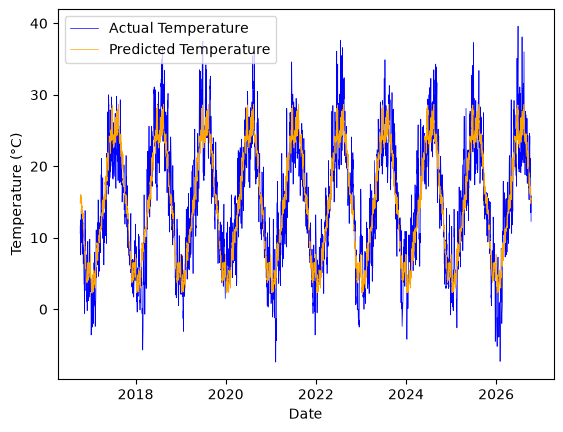

In [ ]:
plt.plot(merged['date'], merged['temperature_2m (°C)'], label='Actual Temperature', color='blue', linewidth=0.5)
plt.plot(merged['date'], merged['predicted_temp'], label='Predicted Temperature', color='orange', linewidth=0.5)
plt.xlabel('Date')
plt.ylabel('Temperature (°C)')
plt.legend()
plt.show()